### Submission 2: Pretrained Models, With and Without Fine-Tuning
### Facial Expression Recognition using CNN on the FER-2013 Dataset

**Course:** CSE366 (Artificial Intelligence)

**Group:** 01

| Name | ID |
|---|---|
| Rafid Rahman Sami | 2023-1-60-116 |
| Abdullah Al Sami | 2023-2-60-147 |
| Sumya Kawsar | 2023=3-60-168 |

> **How to run (Collab):**
> 1. Create a notebook and click **+ Add Input** > add the dataset `Archive.zip`.
> 2. Settings > **Accelerator: GPU** (T4 or P100).
> 3. Run all cells from top to bottom. Results are saved after every run, so if the session stops you can re-run and finished models are skipped.

## A. Overview

**Goal.** Select and fine-tune three pretrained CNN architectures on FER-2013 and compare two training modes for each one.

| Item | What we do |
|---|---|
| **Pretrained architectures (3)** | VGG16, ResNet50, MobileNetV2 (all pretrained on ImageNet) |
| **Mode 1: without fine-tuning** | Feature extraction. The pretrained backbone is frozen, only the new classifier head is trained |
| **Mode 2: with fine-tuning** | Head warm-up first, then the whole backbone is unfrozen and trained with a small learning rate |
| **Epochs** | 30 per run, same for every model and mode |
| **Total runs** | 3 models x 2 modes = 6 main runs (plus extra runs for the overfitting fix) |
| **Overfitting / underfitting** | Diagnosed automatically for every run, then fixed (Section F) |

**Required results (where to find them)**

| Required result | For every model and mode | Section |
|---|---|---|
| Accuracy curve (train vs validation) | Yes | E.1 - E.3 |
| Loss curve (train vs validation) | Yes | E.1 - E.3 |
| Classification report (precision, recall, F1 per class) | Yes, on the test set | E.1 - E.3 |
| Confusion matrix on the test set | Yes (counts and normalised) | E.1 - E.3 |
| Overfitting / underfitting handling | Diagnosis table + fixes | F |
| Model comparison and recommended architecture | Summary table, charts | G, H |

The stratified 85/15 train/validation split, class weights for the imbalance (disgust is only about 1.5% of the data), augmentation and label smoothing.

We found 1,236 duplicate training images, 39 duplicate groups with conflicting labels and **568 test images that also appear in the training set** (data leakage). We therefore (1) remove duplicates and conflicting images from the training data and (2) report test accuracy both on the official test set and on a leak-free test subset.

## B. Setup and data preparation

In [1]:
from google.colab import files
files.upload()   # choose fer2013.zip (or archive.zip)
!unzip -q -o *.zip -d /content

from google.colab import drive
drive.mount('/content/drive')
import os; os.makedirs('/content/drive/MyDrive/fer_sub2', exist_ok=True)


Saving archive.zip to archive (3).zip
caution: filename not matched:  archive (2).zip
caution: filename not matched:  archive (3).zip
caution: filename not matched:  archive.zip
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [2]:
import os
import time
import pickle
import random
import hashlib
from collections import defaultdict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

import tensorflow as tf
from tensorflow import keras
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, f1_score, accuracy_score

# ------------------------- Configuration -------------------------
SEED = 42
IMG_SIZE = 96            # 48x48 faces are upscaled to this size for the pretrained networks
BATCH = 64
EPOCHS = 30              # assignment asks for 30-50 epochs per run
HEAD_WARMUP = 5          # fine-tune mode: epochs with frozen backbone before unfreezing
WEIGHTS = "imagenet"     # pretrained weights
VAL_SPLIT = 0.15
OVERFIT_GAP = 0.15       # train-accuracy minus validation-accuracy above this = overfitting
UNDERFIT_ACC = 0.55      # train and validation accuracy both below this = underfitting
AUTO_FIX = True          # re-train runs that overfit with stronger regularisation (Section F)
RUN_BEFORE_AFTER = True  # extra run without any regularisation, to show the fix works
FORCE_RERUN = False

classes = ["angry", "disgust", "fear", "happy", "neutral", "sad", "surprise"]
NUM_CLASSES = len(classes)

# ------------------------- Reproducibility -----------------------
random.seed(SEED)
np.random.seed(SEED)
keras.utils.set_random_seed(SEED)

print("TensorFlow:", tf.__version__)
gpus = tf.config.list_physical_devices("GPU")
print("GPU available:", gpus if gpus else "NO GPU - training will be very slow. Turn on a GPU accelerator.")

# ------------------------- Dataset location ----------------------
DATA_DIR = '/content/archive'

def has_split(d):
    return os.path.isdir(os.path.join(d, 'train')) and os.path.isdir(os.path.join(d, 'test'))

if not has_split(DATA_DIR):                       # fallback: search /kaggle/input
    for root, dirs, _ in os.walk('/kaggle/input'):
        if 'train' in dirs and 'test' in dirs:
            DATA_DIR = root
            break
if not has_split(DATA_DIR) and has_split('.'):    # fallback: current folder
    DATA_DIR = '.'

train_dir = os.path.join(DATA_DIR, 'train')
test_dir = os.path.join(DATA_DIR, 'test')
assert os.path.isdir(train_dir) and os.path.isdir(test_dir), "Could not find train/ and test/ folders!"
print("Using dataset folder:", DATA_DIR)

OUT_DIR = "/content/drive/MyDrive/fer_sub2"
RESULTS_PATH = os.path.join(OUT_DIR, "submission2_results.pkl")

TensorFlow: 2.21.0
GPU available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Using dataset folder: .


In [3]:
def load_folder(folder):
    images, labels = [], []
    for label, c in enumerate(classes):
        path = os.path.join(folder, c)
        for file in sorted(os.listdir(path)):
            with Image.open(os.path.join(path, file)) as img:
                images.append(np.array(img.convert("L")))
            labels.append(label)
    return np.array(images, dtype=np.uint8), np.array(labels)

x_train, y_train = load_folder(train_dir)
x_test, y_test = load_folder(test_dir)
print("Train:", x_train.shape, " Test:", x_test.shape)

Train: (28709, 48, 48)  Test: (7178, 48, 48)


### B.1 Data cleaning
- **Duplicates:** identical images are kept only once in the training data.
- **Conflicting labels:** if the same image appears with different emotion labels, the label is unreliable, so all copies are removed.
- **Leakage:** test images that are identical to a training image are marked. We keep the official test set unchanged (so our numbers can be compared with other work) but also report accuracy on the leak-free part.

In [4]:
md5 = lambda a: hashlib.md5(a.tobytes()).hexdigest()

train_hash = [md5(a) for a in x_train]
labels_by_hash = defaultdict(set)
for h, l in zip(train_hash, y_train):
    labels_by_hash[h].add(int(l))

# --- test images that also appear in the original training set (leakage) ---
test_hash = [md5(a) for a in x_test]
leak_mask = np.array([h in labels_by_hash for h in test_hash])
print(f"Test images that also appear in train (leakage): {leak_mask.sum()} of {len(x_test)} "
      f"({leak_mask.mean()*100:.1f}%)")

# --- clean the training set ---
keep = np.zeros(len(x_train), dtype=bool)
seen = set()
n_conflict = n_dup = 0
for i, h in enumerate(train_hash):
    if len(labels_by_hash[h]) > 1:      # same image, different labels -> drop every copy
        n_conflict += 1
        continue
    if h in seen:                       # exact duplicate -> keep only the first copy
        n_dup += 1
        continue
    seen.add(h)
    keep[i] = True

print(f"Removed {n_dup} duplicate copies and {n_conflict} images with conflicting labels")
x_clean, y_clean = x_train[keep], y_train[keep]
print("Training images before:", len(x_train), "-> after cleaning:", len(x_clean))

# --- stratified train / validation split ---
idx = np.arange(len(x_clean))
tr_idx, va_idx = train_test_split(idx, test_size=VAL_SPLIT, stratify=y_clean, random_state=SEED)
x_tr, y_tr = x_clean[tr_idx], y_clean[tr_idx]
x_val, y_val = x_clean[va_idx], y_clean[va_idx]

# --- class weights (rare classes count more in the loss) ---
cls_counts = np.bincount(y_tr, minlength=NUM_CLASSES)
class_weight = len(y_tr) / (NUM_CLASSES * cls_counts)
sample_w = class_weight[y_tr].astype("float32")

display(pd.DataFrame({
    "class": classes,
    "train": cls_counts,
    "validation": np.bincount(y_val, minlength=NUM_CLASSES),
    "test": np.bincount(y_test, minlength=NUM_CLASSES),
    "class_weight": np.round(class_weight, 3),
}))
print("Train:", x_tr.shape, " Validation:", x_val.shape, " Test:", x_test.shape)

Test images that also appear in train (leakage): 568 of 7178 (7.9%)
Removed 1168 duplicate copies and 107 images with conflicting labels
Training images before: 28709 -> after cleaning: 27434


,class,train,validation,test,class_weight
0,angry,3258,575,958,1.022
1,disgust,322,57,111,10.345
2,fear,3302,583,1024,1.009
3,happy,6022,1063,1774,0.553
4,neutral,4137,730,1233,0.805
5,sad,4008,708,1247,0.831
6,surprise,2269,400,831,1.468


Train: (23318, 48, 48)  Validation: (4116, 48, 48)  Test: (7178, 48, 48)


In [5]:
def make_ds(x, y, weights=None, shuffle=False):
    xs = x.astype("float32")[..., None]            # (N, 48, 48, 1), raw 0-255 (scaling is inside the model)
    ys = tf.one_hot(y, NUM_CLASSES)
    tensors = (xs, ys) if weights is None else (xs, ys, weights)
    ds = tf.data.Dataset.from_tensor_slices(tensors)
    if shuffle:
        ds = ds.shuffle(len(xs), seed=SEED, reshuffle_each_iteration=True)
    return ds.batch(BATCH).prefetch(tf.data.AUTOTUNE)

train_ds = make_ds(x_tr, y_tr, weights=sample_w, shuffle=True)   # used for training (class-weighted)
train_eval_ds = make_ds(x_tr, y_tr)                              # same images, no augmentation, for diagnosis
val_ds = make_ds(x_val, y_val)
test_ds = make_ds(x_test, y_test)
print("Datasets ready.")

Datasets ready.


## C. Model selection

We chose three pretrained architectures from different families, so the comparison teaches us something:

| Model | Family | Conv-base parameters | Why we chose it |
|---|---|---|---|
| **VGG16** | Plain deep stack of 3x3 convolutions | about 14.7 M | The best published single-network result on FER-2013 used a VGG network (Khaireddin and Chen, 2021: 73.28%) |
| **ResNet50** | Residual network (skip connections) | about 23.6 M | Residual networks were part of the strongest FER-2013 results (Pramerdorfer and Kampel, 2016); skip connections make deep networks easier to train |
| **MobileNetV2** | Lightweight (depthwise separable convolutions, inverted residuals) | about 2.3 M | Small and fast, so it is the realistic choice for the real-time webcam demo planned for the final project |

### C.1 How we adapt a 48x48 grayscale face to an ImageNet model
Training, testing and the later webcam demo all use the same raw 0-255 input.

`48x48x1 face` > **augmentation** (training only) > **resize to 96x96** > **repeat the gray channel 3 times** (RGB) > **model-specific ImageNet normalisation** > **pretrained backbone** > global average pooling > Dropout > Dense(256) > Dropout > Dense(7, softmax)

### C.2 Regularisation levels
| Level | Augmentation (rotation / shift / zoom + flip) | Dropout | L2 weight penalty | Label smoothing | Used for |
|---|---|---|---|---|---|
| 0 | none | none | none | 0 | "before the fix" demonstration only |
| 1 | 0.08 / 0.10 / 0.10 | 0.4, 0.3 | 1e-4 | 0.10 | all main runs |
| 2 | 0.15 / 0.15 / 0.15 | 0.5, 0.5 | 5e-4 | 0.15 | automatic fix for runs that still overfit |

Besides these, every run uses class weights, `ReduceLROnPlateau` (halves the learning rate when validation loss stalls) and keeps the **best-validation-accuracy weights**

In [6]:
MODEL_ZOO = {
    # prep: 'caffe' = BGR mean subtraction (VGG16, ResNet50) ; 'tf' = scale to [-1, 1] (MobileNetV2)
    # ft_lr: learning rate used while the whole backbone is fine-tuned (small, to keep pretrained knowledge)
    "VGG16":       dict(builder=keras.applications.VGG16,       prep="caffe", ft_lr=1e-5),
    "ResNet50":    dict(builder=keras.applications.ResNet50,    prep="caffe", ft_lr=5e-5),
    "MobileNetV2": dict(builder=keras.applications.MobileNetV2, prep="tf",    ft_lr=1e-4),
}
MODES = ["frozen", "finetune"]
MODE_TITLE = {"frozen": "Without fine-tuning (frozen backbone)", "finetune": "With fine-tuning"}

REG = {
    0: dict(aug=None,             drop1=0.0, drop2=0.0, l2=0.0,  ls=0.0),
    1: dict(aug=(0.08, 0.10, 0.10), drop1=0.4, drop2=0.3, l2=1e-4, ls=0.10),
    2: dict(aug=(0.15, 0.15, 0.15), drop1=0.5, drop2=0.5, l2=5e-4, ls=0.15),
}

def augmentation(rot, shift, zoom):
    return keras.Sequential([
        keras.layers.RandomFlip("horizontal"),
        keras.layers.RandomRotation(rot),
        keras.layers.RandomTranslation(shift, shift),
        keras.layers.RandomZoom(zoom),
    ])

def to_rgb_and_normalise(x, prep):
    # gray -> 3 channels + the normalisation the ImageNet weights expect
    if prep == "tf":
        x = keras.layers.Concatenate()([x, x, x])
        return keras.layers.Rescaling(1.0 / 127.5, offset=-1.0)(x)
    means_bgr = (103.939, 116.779, 123.68)
    chans = [keras.layers.Rescaling(1.0, offset=-m)(x) for m in means_bgr]
    return keras.layers.Concatenate()(chans)

def build_model(name, level):
    cfg, reg = MODEL_ZOO[name], REG[level]
    inp = keras.Input(shape=(48, 48, 1))
    x = inp
    if reg["aug"] is not None:
        x = augmentation(*reg["aug"])(x)                 # active only during training
    x = keras.layers.Resizing(IMG_SIZE, IMG_SIZE)(x)
    x = to_rgb_and_normalise(x, cfg["prep"])

    base = cfg["builder"](include_top=False, weights=WEIGHTS, input_shape=(IMG_SIZE, IMG_SIZE, 3))
    base.trainable = False
    x = base(x, training=False)                          # BatchNorm stays in inference mode, also when fine-tuning
    x = keras.layers.GlobalAveragePooling2D()(x)
    if reg["drop1"] > 0:
        x = keras.layers.Dropout(reg["drop1"])(x)
    l2 = keras.regularizers.l2(reg["l2"]) if reg["l2"] > 0 else None
    x = keras.layers.Dense(256, activation="relu", kernel_regularizer=l2)(x)
    if reg["drop2"] > 0:
        x = keras.layers.Dropout(reg["drop2"])(x)
    out = keras.layers.Dense(NUM_CLASSES, activation="softmax")(x)
    return keras.Model(inp, out, name=name), base

# quick look at one model
_m, _b = build_model("MobileNetV2", 1)
print("MobileNetV2 total params:", f"{_m.count_params():,}", "| backbone:", f"{_b.count_params():,}")
del _m, _b

MobileNetV2 total params: 2,587,719 | backbone: 2,257,984


## D. Training strategy

| | Mode 1: without fine-tuning | Mode 2: with fine-tuning |
|---|---|---|
| Backbone | frozen for all 30 epochs | frozen for 5 epochs (head warm-up), then **fully unfrozen** for 25 epochs |
| Learning rate | 1e-3 for the head | 1e-3 during warm-up, then a small model-specific rate (VGG16 1e-5, ResNet50 5e-5, MobileNetV2 1e-4) |
| Trainable parameters | only the new head | the whole network |
| Idea | use ImageNet features as they are | adapt ImageNet features to low-resolution gray faces |

**Overfitting / underfitting diagnosis (automatic).** After training, we reload the best weights and measure accuracy on the training images **without augmentation or dropout** (a fair measurement), on the validation set and on the test set.

| Symptom | Diagnosis | Fix used |
|---|---|---|
| train accuracy minus validation accuracy > 0.15 | **Overfitting** | retrain with regularisation level 2 (stronger augmentation, dropout, L2, label smoothing) and keep it if validation accuracy is better |
| train and validation accuracy both < 0.55 | **Underfitting** | unfreeze the backbone (fine-tuning mode), keep training longer at a suitable learning rate |

In [7]:
RESULTS = {}
if os.path.exists(RESULTS_PATH) and not FORCE_RERUN:
    with open(RESULTS_PATH, "rb") as f:
        RESULTS = pickle.load(f)
    print("Loaded earlier results:", list(RESULTS.keys()))

def diagnose(train_acc, val_acc):
    gap = train_acc - val_acc
    if gap > OVERFIT_GAP:
        return "overfitting"
    if train_acc < UNDERFIT_ACC and val_acc < UNDERFIT_ACC:
        return "underfitting"
    return "good fit"

def run_experiment(name, mode, level=1):
    key = f"{name}|{mode}|L{level}"
    if key in RESULTS:
        print(f"[skip] {key} already finished (loaded from file)")
        return RESULTS[key]

    print(f"\n{'='*70}\nTraining {name} | {MODE_TITLE[mode]} | regularisation level {level}\n{'='*70}")
    keras.backend.clear_session()
    keras.utils.set_random_seed(SEED)

    model, base = build_model(name, level)
    cfg = MODEL_ZOO[name]
    loss = keras.losses.CategoricalCrossentropy(label_smoothing=REG[level]["ls"])
    ckpt = os.path.join(OUT_DIR, f"{name}_{mode}_L{level}.weights.h5")
    hist = {"accuracy": [], "val_accuracy": [], "loss": [], "val_loss": []}

    def fit_stage(epochs, lr, init_best=None):
        model.compile(optimizer=keras.optimizers.Adam(lr), loss=loss, metrics=["accuracy"])
        callbacks = [
            keras.callbacks.ModelCheckpoint(ckpt, monitor="val_accuracy", mode="max", save_best_only=True,
                                            save_weights_only=True, initial_value_threshold=init_best),
            keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3, min_lr=1e-7, verbose=1),
        ]
        h = model.fit(train_ds, validation_data=val_ds, epochs=epochs, callbacks=callbacks, verbose=2)
        for k in hist:
            hist[k] += [float(v) for v in h.history[k]]
        return max(h.history["val_accuracy"])

    t0 = time.time()
    unfreeze_epoch = None
    if mode == "frozen":
        fit_stage(EPOCHS, 1e-3)
    else:
        best = fit_stage(HEAD_WARMUP, 1e-3)               # stage 1: train the head only
        unfreeze_epoch = HEAD_WARMUP
        base.trainable = True                              # stage 2: unfreeze the whole backbone
        fit_stage(EPOCHS - HEAD_WARMUP, cfg["ft_lr"], init_best=best)
    minutes = (time.time() - t0) / 60

    model.load_weights(ckpt)                               # go back to the best epoch
    train_loss, train_acc = model.evaluate(train_eval_ds, verbose=0)
    val_loss, val_acc = model.evaluate(val_ds, verbose=0)
    val_probs = model.predict(val_ds, verbose=0)
    test_probs = model.predict(test_ds, verbose=0)
    trainable = int(sum(np.prod(w.shape) for w in model.trainable_weights))

    yp = test_probs.argmax(1)
    res = dict(
        key=key, name=name, mode=mode, level=level, history=hist, unfreeze_epoch=unfreeze_epoch,
        best_epoch=int(np.argmax(hist["val_accuracy"])) + 1, minutes=minutes, trainable_params=trainable,
        train_acc=float(train_acc), val_acc=float(val_acc),
        val_macro_f1=float(f1_score(y_val, val_probs.argmax(1), average="macro")),
        test_probs=test_probs,
        test_acc=float(accuracy_score(y_test, yp)),
        clean_test_acc=float(accuracy_score(y_test[~leak_mask], yp[~leak_mask])),
        macro_f1=float(f1_score(y_test, yp, average="macro")),
        weighted_f1=float(f1_score(y_test, yp, average="weighted")),
    )
    res["gap"] = res["train_acc"] - res["val_acc"]
    res["diagnosis"] = diagnose(res["train_acc"], res["val_acc"])

    RESULTS[key] = res
    with open(RESULTS_PATH, "wb") as f:
        pickle.dump(RESULTS, f)
    print(f"Finished in {minutes:.1f} min | best epoch {res['best_epoch']} | "
          f"train {res['train_acc']:.3f} | val {res['val_acc']:.3f} | test {res['test_acc']:.3f} | {res['diagnosis']}")
    return res

In [8]:
def show_report(probs, title):
    # classification report + confusion matrix on the TEST set
    y_pred = probs.argmax(1)
    print(f"\n{title}")
    print(f"Test accuracy: {accuracy_score(y_test, y_pred):.4f}")
    print(classification_report(y_test, y_pred, target_names=classes, digits=3, zero_division=0))
    cm = confusion_matrix(y_test, y_pred, labels=range(NUM_CLASSES))
    cm_norm = cm / cm.sum(axis=1, keepdims=True)
    fig, ax = plt.subplots(1, 2, figsize=(15, 5.5))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=classes, yticklabels=classes, ax=ax[0])
    ax[0].set_title("Confusion matrix (counts)")
    sns.heatmap(cm_norm, annot=True, fmt=".2f", cmap="Blues", xticklabels=classes, yticklabels=classes,
                ax=ax[1], vmin=0, vmax=1)
    ax[1].set_title("Confusion matrix (each row = 100% of that true class)")
    for a in ax:
        a.set_xlabel("Predicted")
        a.set_ylabel("True")
    plt.suptitle(title)
    plt.tight_layout()
    plt.show()

def show_run(res, note=""):
    h = res["history"]
    ep = np.arange(1, len(h["accuracy"]) + 1)
    title = f"{res['name']} - {MODE_TITLE[res['mode']]}{note}"
    fig, ax = plt.subplots(1, 2, figsize=(14, 4.2))
    for a, (tr, va, ylabel) in zip(ax, [("accuracy", "val_accuracy", "Accuracy"), ("loss", "val_loss", "Loss")]):
        a.plot(ep, h[tr], label="train", lw=2)
        a.plot(ep, h[va], label="validation", lw=2)
        a.axvline(res["best_epoch"], color="green", ls=":", label=f"best epoch ({res['best_epoch']})")
        if res["unfreeze_epoch"]:
            a.axvline(res["unfreeze_epoch"] + 0.5, color="gray", ls="--", label="backbone unfrozen")
        a.set_xlabel("Epoch")
        a.set_ylabel(ylabel)
        a.set_title(f"{ylabel} curve")
        a.grid(alpha=0.3)
        a.legend()
    plt.suptitle(title)
    plt.tight_layout()
    plt.show()
    print(f"Train acc (no augmentation): {res['train_acc']:.3f} | Validation acc: {res['val_acc']:.3f} | "
          f"Gap: {res['gap']:+.3f} | Diagnosis: {res['diagnosis'].upper()}")
    print(f"Test acc: {res['test_acc']:.3f} | Test acc without leaked images: {res['clean_test_acc']:.3f} | "
          f"Macro-F1: {res['macro_f1']:.3f} | Training time: {res['minutes']:.1f} min")
    show_report(res["test_probs"], title)

## E. Experiments: every model, both modes
For each run we get: accuracy curve, loss curve, classification report and confusion matrix on the test set.


### E.1 VGG16
A plain stack of 3x3 convolutions (13 conv layers). Simple and strong on FER-2013 in the literature, but heavy.


Training VGG16 | Without fine-tuning (frozen backbone) | regularisation level 1
Epoch 1/30
365/365 - 30s - 84ms/step - accuracy: 0.1808 - loss: 3.0728 - val_accuracy: 0.2366 - val_loss: 1.9146 - learning_rate: 0.0010
Epoch 2/30
365/365 - 22s - 61ms/step - accuracy: 0.1953 - loss: 1.9628 - val_accuracy: 0.2988 - val_loss: 1.8505 - learning_rate: 0.0010
Epoch 3/30
365/365 - 22s - 61ms/step - accuracy: 0.2161 - loss: 1.9173 - val_accuracy: 0.3353 - val_loss: 1.8137 - learning_rate: 0.0010
Epoch 4/30
365/365 - 23s - 62ms/step - accuracy: 0.2383 - loss: 1.8908 - val_accuracy: 0.3472 - val_loss: 1.7969 - learning_rate: 0.0010
Epoch 5/30
365/365 - 23s - 64ms/step - accuracy: 0.2616 - loss: 1.8703 - val_accuracy: 0.3486 - val_loss: 1.7733 - learning_rate: 0.0010
Epoch 6/30
365/365 - 41s - 113ms/step - accuracy: 0.2637 - loss: 1.8609 - val_accuracy: 0.3554 - val_loss: 1.7525 - learning_rate: 0.0010
Epoch 7/30
365/365 - 22s - 61ms/step - accuracy: 0.2755 - loss: 1.8582 - val_accuracy: 0.3516 - 

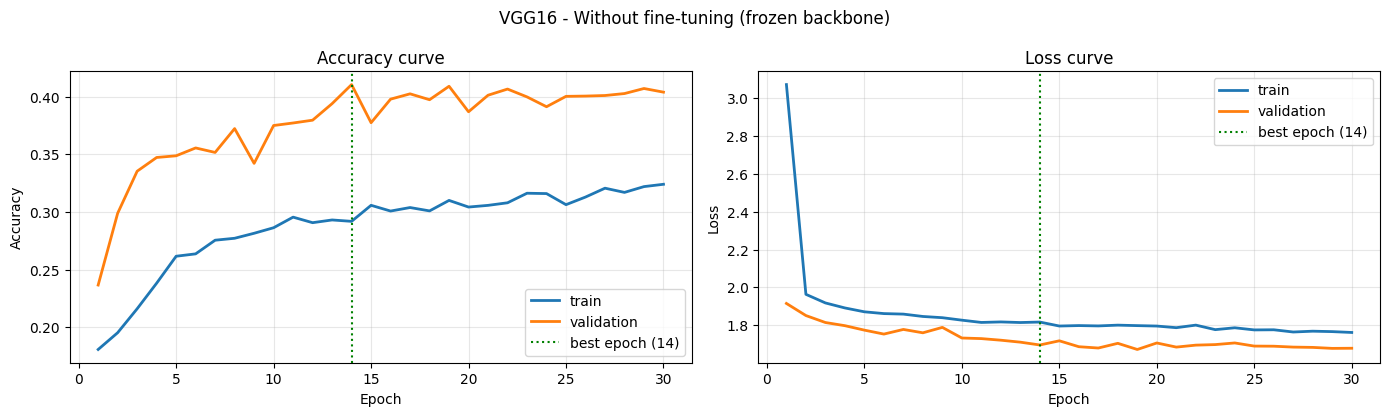

Train acc (no augmentation): 0.418 | Validation acc: 0.410 | Gap: +0.008 | Diagnosis: UNDERFITTING
Test acc: 0.405 | Test acc without leaked images: 0.402 | Macro-F1: 0.339 | Training time: 11.6 min

VGG16 - Without fine-tuning (frozen backbone)
Test accuracy: 0.4046
              precision    recall  f1-score   support

       angry      0.281     0.285     0.283       958
     disgust      0.122     0.126     0.124       111
        fear      0.302     0.131     0.183      1024
       happy      0.440     0.723     0.547      1774
     neutral      0.364     0.393     0.378      1233
         sad      0.398     0.229     0.291      1247
    surprise      0.629     0.516     0.567       831

    accuracy                          0.405      7178
   macro avg      0.362     0.343     0.339      7178
weighted avg      0.396     0.405     0.382      7178



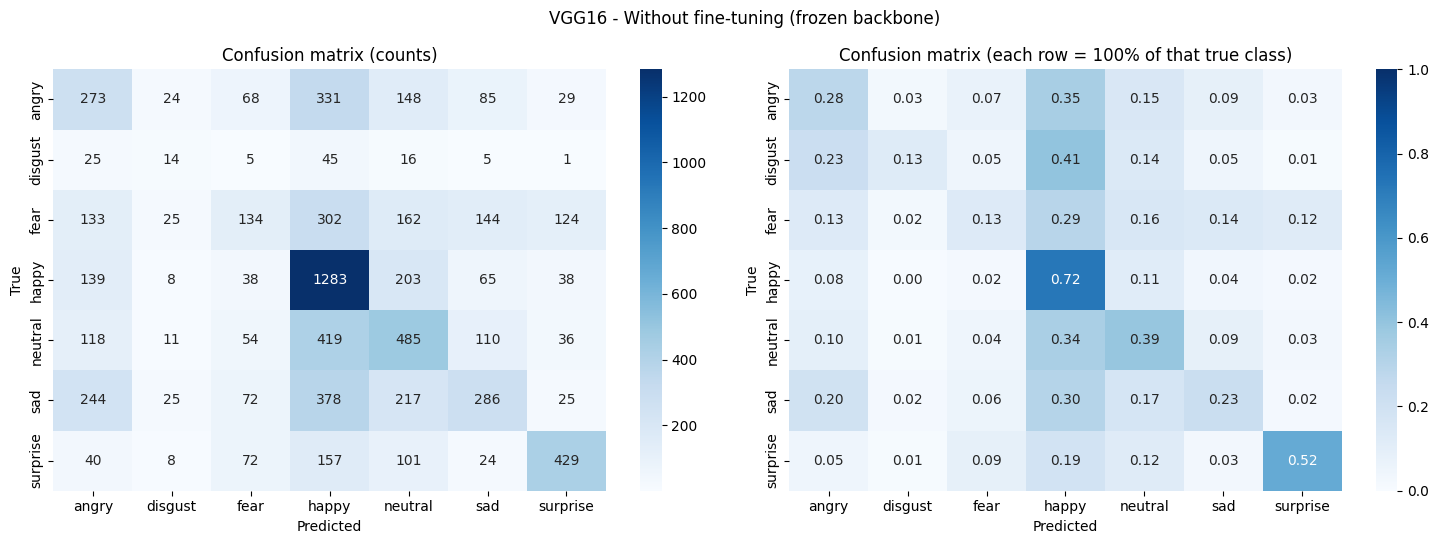


Training VGG16 | With fine-tuning | regularisation level 1
Epoch 1/5
365/365 - 24s - 67ms/step - accuracy: 0.1727 - loss: 2.9970 - val_accuracy: 0.2682 - val_loss: 1.8860 - learning_rate: 0.0010
Epoch 2/5
365/365 - 23s - 64ms/step - accuracy: 0.2031 - loss: 1.9566 - val_accuracy: 0.3161 - val_loss: 1.8552 - learning_rate: 0.0010
Epoch 3/5
365/365 - 22s - 60ms/step - accuracy: 0.2222 - loss: 1.9219 - val_accuracy: 0.3076 - val_loss: 1.8444 - learning_rate: 0.0010
Epoch 4/5
365/365 - 23s - 64ms/step - accuracy: 0.2318 - loss: 1.8860 - val_accuracy: 0.3450 - val_loss: 1.7945 - learning_rate: 0.0010
Epoch 5/5
365/365 - 23s - 64ms/step - accuracy: 0.2493 - loss: 1.8731 - val_accuracy: 0.3610 - val_loss: 1.7562 - learning_rate: 0.0010
Epoch 1/25
365/365 - 81s - 223ms/step - accuracy: 0.2961 - loss: 1.8115 - val_accuracy: 0.3851 - val_loss: 1.6738 - learning_rate: 1.0000e-05
Epoch 2/25
365/365 - 68s - 187ms/step - accuracy: 0.3522 - loss: 1.7404 - val_accuracy: 0.4281 - val_loss: 1.5927 - le

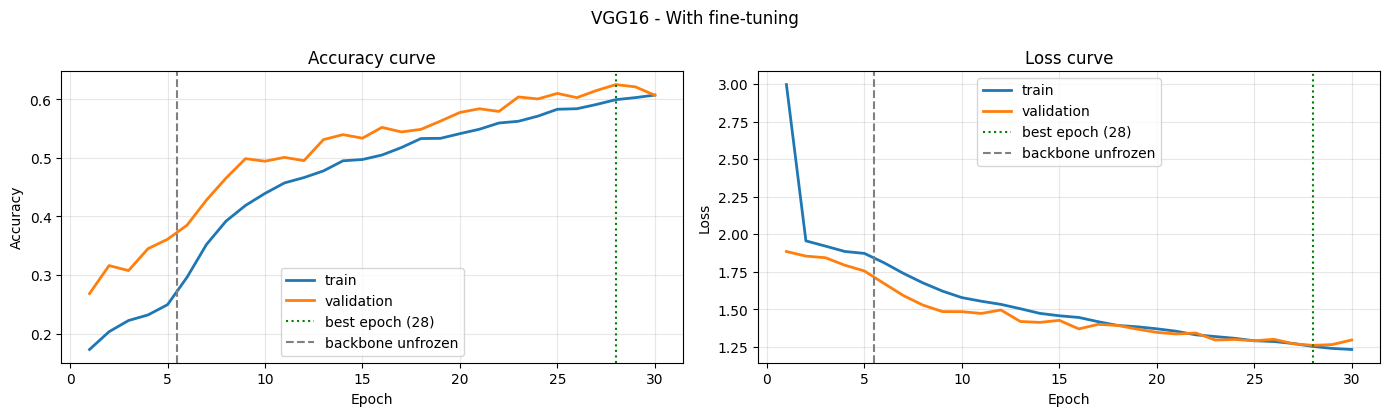

Train acc (no augmentation): 0.649 | Validation acc: 0.625 | Gap: +0.024 | Diagnosis: GOOD FIT
Test acc: 0.617 | Test acc without leaked images: 0.606 | Macro-F1: 0.598 | Training time: 30.4 min

VGG16 - With fine-tuning
Test accuracy: 0.6172
              precision    recall  f1-score   support

       angry      0.516     0.575     0.544       958
     disgust      0.643     0.568     0.603       111
        fear      0.429     0.389     0.408      1024
       happy      0.845     0.851     0.848      1774
     neutral      0.561     0.616     0.588      1233
         sad      0.477     0.427     0.451      1247
    surprise      0.744     0.741     0.743       831

    accuracy                          0.617      7178
   macro avg      0.602     0.595     0.598      7178
weighted avg      0.614     0.617     0.615      7178



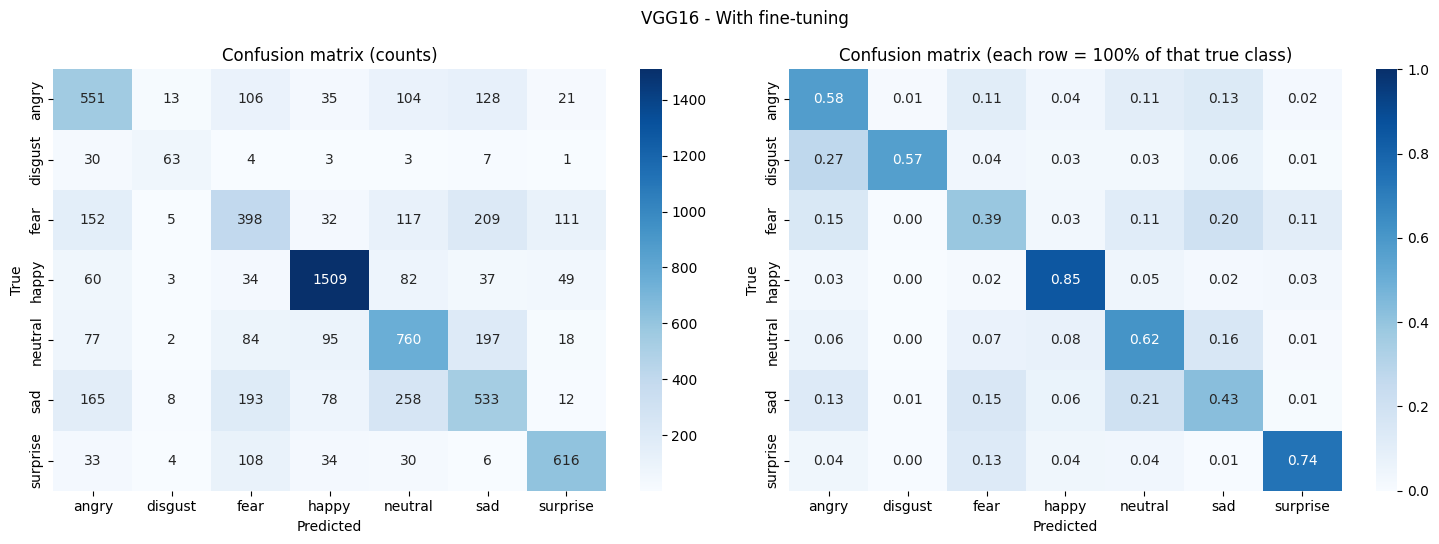

In [9]:
for mode in MODES:
    show_run(run_experiment("VGG16", mode, level=1))

### E.2 ResNet50
50 layers with residual connections, which let gradients flow and make deep networks easier to fine-tune.


Training ResNet50 | Without fine-tuning (frozen backbone) | regularisation level 1
94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/30
365/365 - 38s - 105ms/step - accuracy: 0.2448 - loss: 2.0164 - val_accuracy: 0.3440 - val_loss: 1.8263 - learning_rate: 0.0010
Epoch 2/30
365/365 - 26s - 72ms/step - accuracy: 0.2948 - loss: 1.8547 - val_accuracy: 0.3785 - val_loss: 1.7303 - learning_rate: 0.0010
Epoch 3/30
365/365 - 26s - 72ms/step - accuracy: 0.3140 - loss: 1.8193 - val_accuracy: 0.3953 - val_loss: 1.7232 - learning_rate: 0.0010
Epoch 4/30
365/365 - 26s - 72ms/step - accuracy: 0.3191 - loss: 1.8060 - val_accuracy: 0.4050 - val_loss: 1.7142 - learning_rate: 0.0010
Epoch 5/30
365/365 - 26s - 72ms/step - accuracy: 0.3291 - loss: 1.7873 - val_accuracy: 0.4201 - val_loss: 1.6598 - learning_rate: 0.0010
Epoch 6/30
365/365 - 24s - 66ms/step - accuracy: 0.3289 - loss: 1.7808 - val_accuracy: 0.4108 - val_loss: 1.6704 - learning_rate: 0.0010
Epoch 7/30
365/365 - 24s - 66ms/step - acc

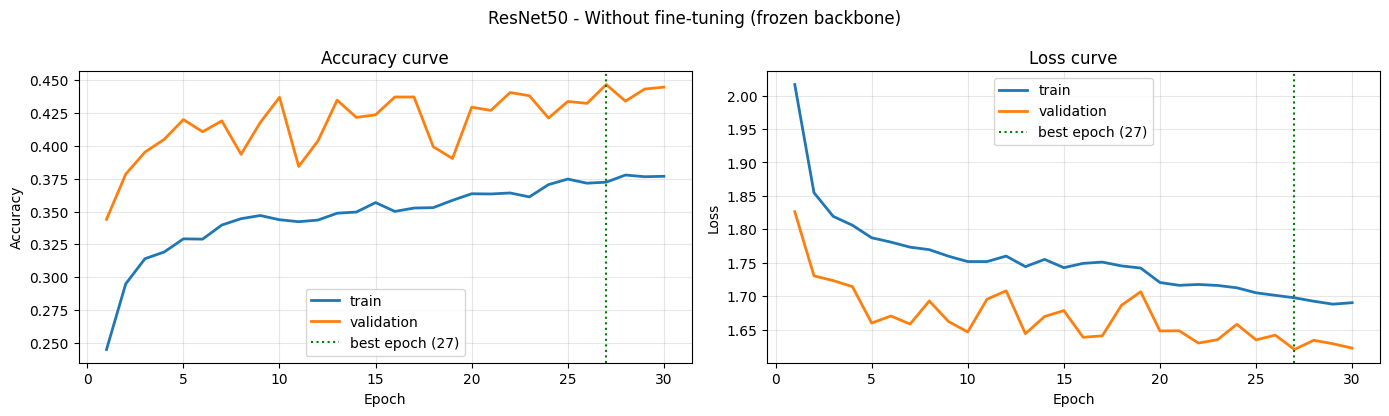

Train acc (no augmentation): 0.468 | Validation acc: 0.447 | Gap: +0.021 | Diagnosis: UNDERFITTING
Test acc: 0.462 | Test acc without leaked images: 0.449 | Macro-F1: 0.405 | Training time: 12.7 min

ResNet50 - Without fine-tuning (frozen backbone)
Test accuracy: 0.4621
              precision    recall  f1-score   support

       angry      0.348     0.377     0.362       958
     disgust      0.120     0.333     0.176       111
        fear      0.372     0.198     0.259      1024
       happy      0.642     0.618     0.630      1774
     neutral      0.402     0.534     0.459      1233
         sad      0.481     0.276     0.351      1247
    surprise      0.502     0.742     0.599       831

    accuracy                          0.462      7178
   macro avg      0.410     0.440     0.405      7178
weighted avg      0.471     0.462     0.453      7178



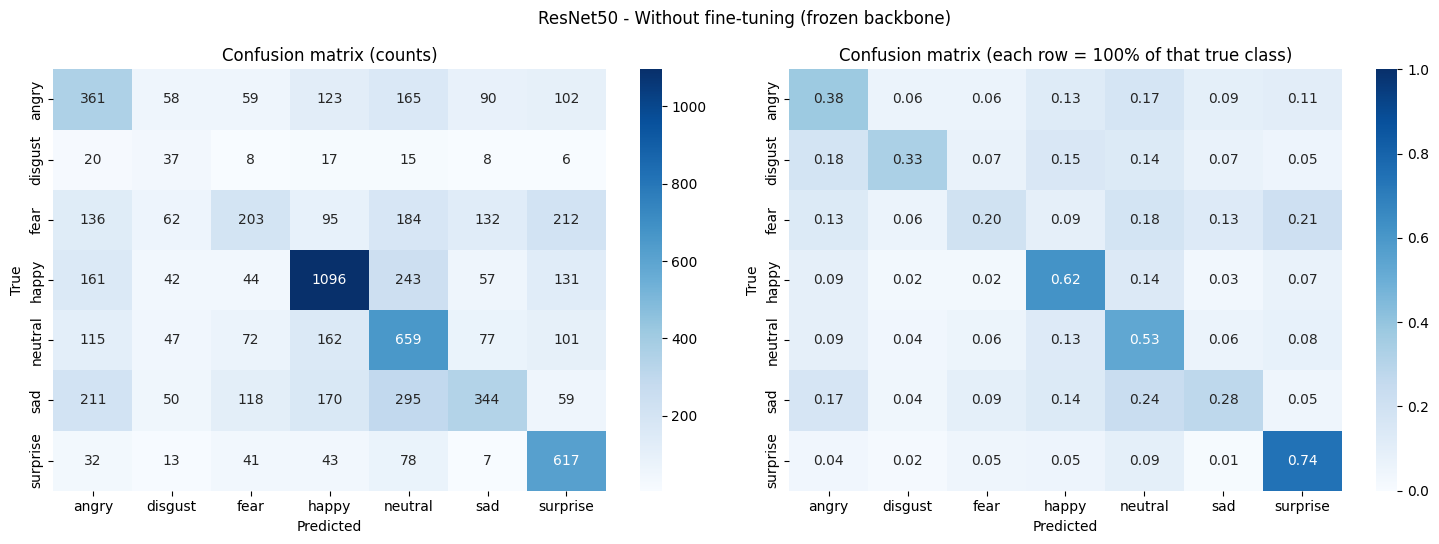


Training ResNet50 | With fine-tuning | regularisation level 1
Epoch 1/5
365/365 - 34s - 93ms/step - accuracy: 0.2630 - loss: 2.0150 - val_accuracy: 0.3433 - val_loss: 1.7757 - learning_rate: 0.0010
Epoch 2/5
365/365 - 24s - 66ms/step - accuracy: 0.2984 - loss: 1.8515 - val_accuracy: 0.3394 - val_loss: 1.7870 - learning_rate: 0.0010
Epoch 3/5
365/365 - 26s - 72ms/step - accuracy: 0.3173 - loss: 1.8249 - val_accuracy: 0.3919 - val_loss: 1.7057 - learning_rate: 0.0010
Epoch 4/5
365/365 - 26s - 72ms/step - accuracy: 0.3191 - loss: 1.8053 - val_accuracy: 0.4035 - val_loss: 1.6917 - learning_rate: 0.0010
Epoch 5/5
365/365 - 24s - 67ms/step - accuracy: 0.3260 - loss: 1.7896 - val_accuracy: 0.3800 - val_loss: 1.7361 - learning_rate: 0.0010
Epoch 1/25
365/365 - 136s - 372ms/step - accuracy: 0.3102 - loss: 1.8491 - val_accuracy: 0.4320 - val_loss: 1.6120 - learning_rate: 5.0000e-05
Epoch 2/25
365/365 - 98s - 269ms/step - accuracy: 0.4086 - loss: 1.6377 - val_accuracy: 0.4830 - val_loss: 1.5362 

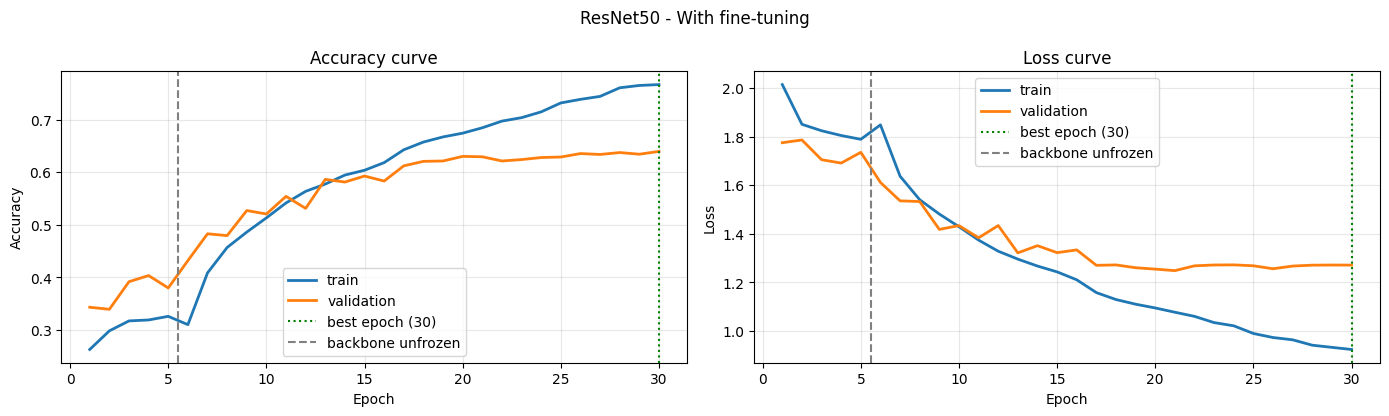

Train acc (no augmentation): 0.784 | Validation acc: 0.640 | Gap: +0.145 | Diagnosis: GOOD FIT
Test acc: 0.646 | Test acc without leaked images: 0.630 | Macro-F1: 0.638 | Training time: 43.4 min

ResNet50 - With fine-tuning
Test accuracy: 0.6461
              precision    recall  f1-score   support

       angry      0.563     0.556     0.560       958
     disgust      0.636     0.739     0.683       111
        fear      0.477     0.450     0.463      1024
       happy      0.897     0.822     0.858      1774
     neutral      0.584     0.637     0.609      1233
         sad      0.513     0.538     0.525      1247
    surprise      0.754     0.780     0.767       831

    accuracy                          0.646      7178
   macro avg      0.632     0.646     0.638      7178
weighted avg      0.652     0.646     0.648      7178



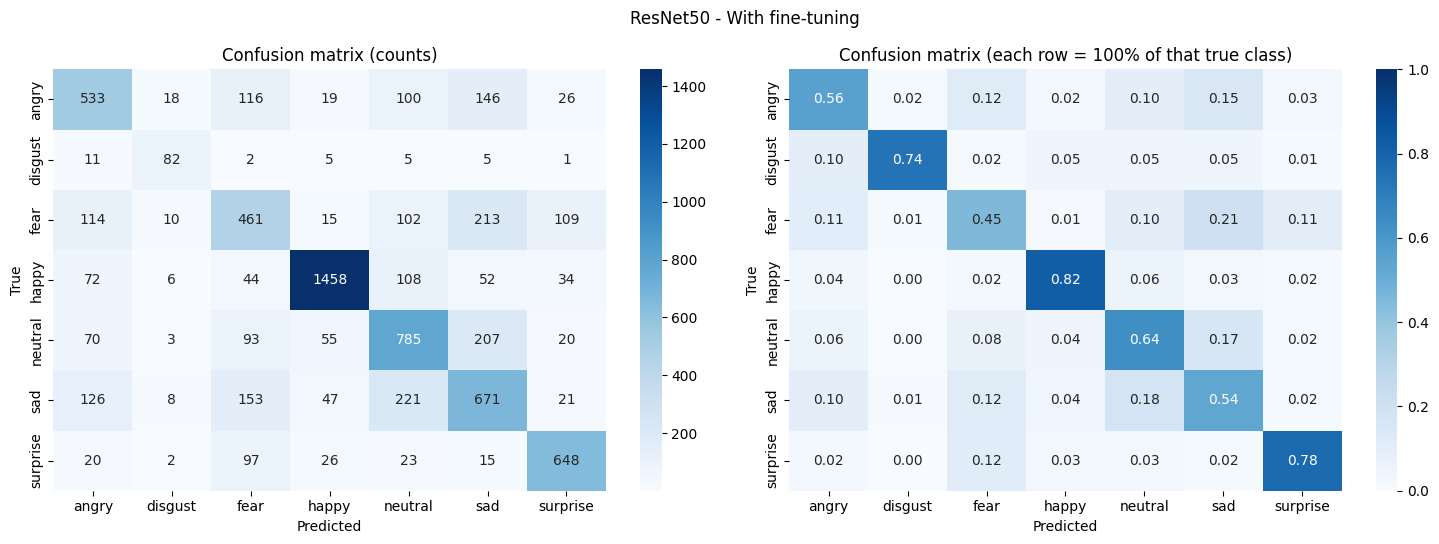

In [10]:
for mode in MODES:
    show_run(run_experiment("ResNet50", mode, level=1))

### E.3 MobileNetV2
A lightweight network with about one tenth of the ResNet50 parameters. Important for real-time use.


Training MobileNetV2 | Without fine-tuning (frozen backbone) | regularisation level 1
Epoch 1/30
365/365 - 22s - 60ms/step - accuracy: 0.2278 - loss: 1.9659 - val_accuracy: 0.3083 - val_loss: 1.8322 - learning_rate: 0.0010
Epoch 2/30
365/365 - 11s - 30ms/step - accuracy: 0.2775 - loss: 1.8511 - val_accuracy: 0.3137 - val_loss: 1.8121 - learning_rate: 0.0010
Epoch 3/30
365/365 - 11s - 30ms/step - accuracy: 0.2960 - loss: 1.8363 - val_accuracy: 0.3530 - val_loss: 1.7797 - learning_rate: 0.0010
Epoch 4/30
365/365 - 11s - 31ms/step - accuracy: 0.2975 - loss: 1.8160 - val_accuracy: 0.3576 - val_loss: 1.7828 - learning_rate: 0.0010
Epoch 5/30
365/365 - 11s - 30ms/step - accuracy: 0.3040 - loss: 1.7997 - val_accuracy: 0.3732 - val_loss: 1.7357 - learning_rate: 0.0010
Epoch 6/30
365/365 - 11s - 31ms/step - accuracy: 0.2992 - loss: 1.8011 - val_accuracy: 0.3489 - val_loss: 1.7854 - learning_rate: 0.0010
Epoch 7/30
365/365 - 10s - 27ms/step - accuracy: 0.3087 - loss: 1.7881 - val_accuracy: 0.35

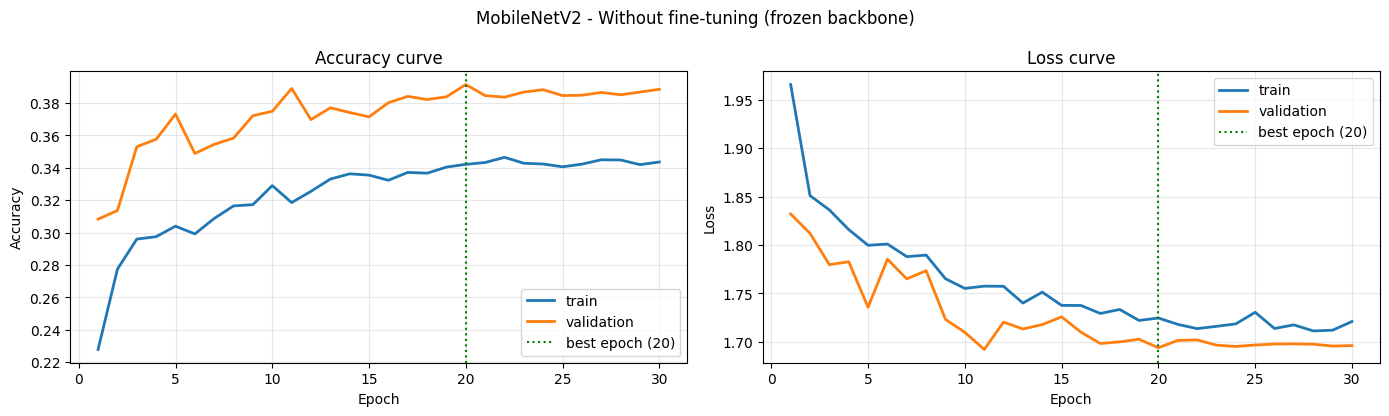

Train acc (no augmentation): 0.393 | Validation acc: 0.391 | Gap: +0.002 | Diagnosis: UNDERFITTING
Test acc: 0.395 | Test acc without leaked images: 0.389 | Macro-F1: 0.338 | Training time: 5.5 min

MobileNetV2 - Without fine-tuning (frozen backbone)
Test accuracy: 0.3947
              precision    recall  f1-score   support

       angry      0.261     0.347     0.298       958
     disgust      0.114     0.153     0.131       111
        fear      0.297     0.204     0.242      1024
       happy      0.483     0.606     0.537      1774
     neutral      0.348     0.444     0.390      1233
         sad      0.457     0.131     0.203      1247
    surprise      0.546     0.590     0.567       831

    accuracy                          0.395      7178
   macro avg      0.358     0.353     0.338      7178
weighted avg      0.401     0.395     0.377      7178



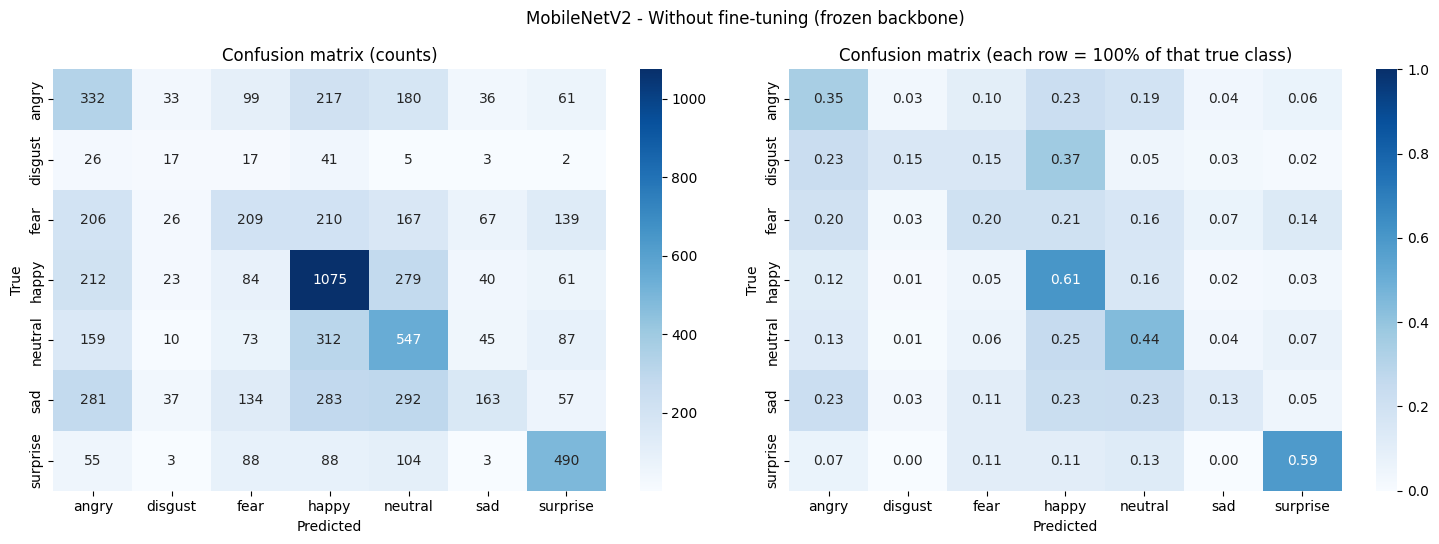


Training MobileNetV2 | With fine-tuning | regularisation level 1
Epoch 1/5
365/365 - 18s - 51ms/step - accuracy: 0.2316 - loss: 1.9704 - val_accuracy: 0.3341 - val_loss: 1.8061 - learning_rate: 0.0010
Epoch 2/5
365/365 - 11s - 30ms/step - accuracy: 0.2756 - loss: 1.8557 - val_accuracy: 0.3535 - val_loss: 1.7638 - learning_rate: 0.0010
Epoch 3/5
365/365 - 11s - 30ms/step - accuracy: 0.2970 - loss: 1.8326 - val_accuracy: 0.3404 - val_loss: 1.8041 - learning_rate: 0.0010
Epoch 4/5
365/365 - 11s - 29ms/step - accuracy: 0.2980 - loss: 1.8124 - val_accuracy: 0.3499 - val_loss: 1.8006 - learning_rate: 0.0010
Epoch 5/5
365/365 - 11s - 31ms/step - accuracy: 0.3042 - loss: 1.7990 - val_accuracy: 0.3618 - val_loss: 1.7425 - learning_rate: 0.0010
Epoch 1/25
365/365 - 76s - 208ms/step - accuracy: 0.2758 - loss: 1.8829 - val_accuracy: 0.2636 - val_loss: 1.9509 - learning_rate: 1.0000e-04
Epoch 2/25
365/365 - 46s - 126ms/step - accuracy: 0.3722 - loss: 1.6946 - val_accuracy: 0.2694 - val_loss: 1.979

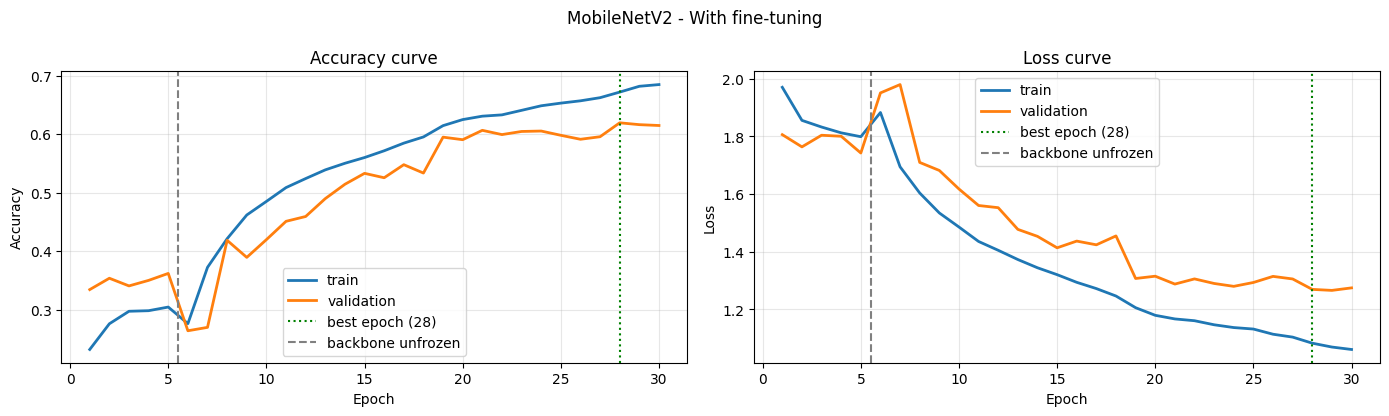

Train acc (no augmentation): 0.674 | Validation acc: 0.620 | Gap: +0.054 | Diagnosis: GOOD FIT
Test acc: 0.608 | Test acc without leaked images: 0.595 | Macro-F1: 0.578 | Training time: 22.0 min

MobileNetV2 - With fine-tuning
Test accuracy: 0.6082
              precision    recall  f1-score   support

       angry      0.482     0.571     0.522       958
     disgust      0.537     0.459     0.495       111
        fear      0.460     0.357     0.402      1024
       happy      0.864     0.806     0.834      1774
     neutral      0.529     0.614     0.568      1233
         sad      0.488     0.496     0.492      1247
    surprise      0.747     0.718     0.733       831

    accuracy                          0.608      7178
   macro avg      0.587     0.575     0.578      7178
weighted avg      0.614     0.608     0.609      7178



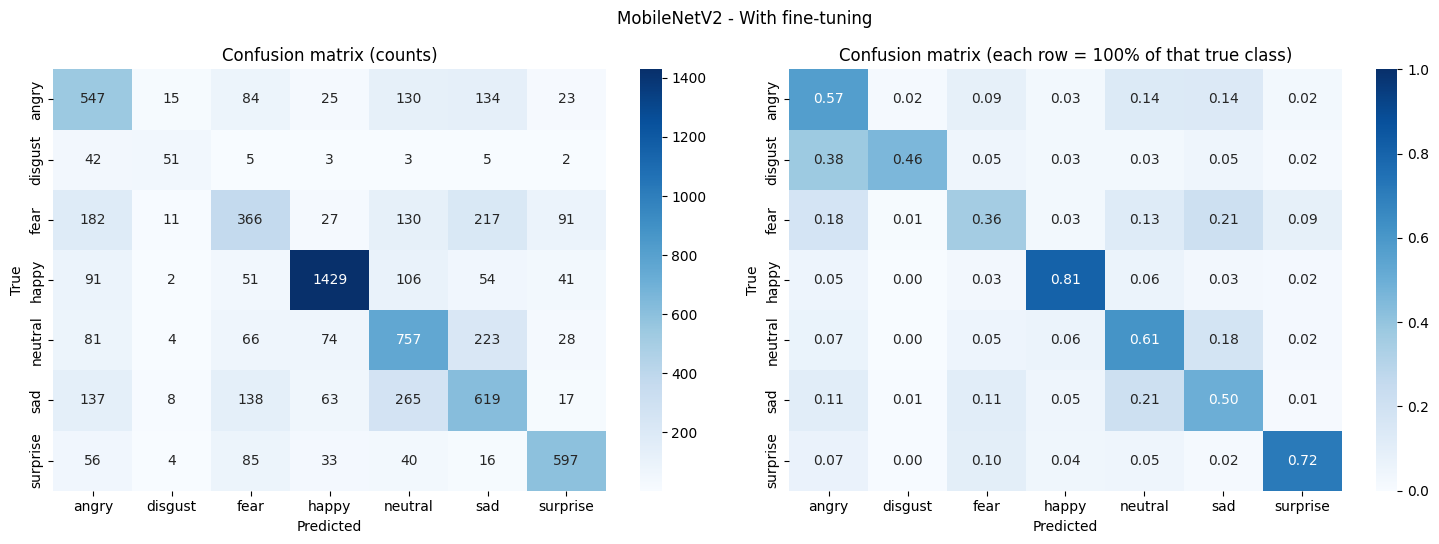

In [11]:
for mode in MODES:
    show_run(run_experiment("MobileNetV2", mode, level=1))

## F. Overfitting and underfitting: diagnosis and fixes

### F.1 Diagnosis of all main runs
Train accuracy is measured **without** augmentation and dropout, validation accuracy on the held-out 15% of the training data.

In [12]:
rows = []
for name in MODEL_ZOO:
    for mode in MODES:
        r = RESULTS[f"{name}|{mode}|L1"]
        rows.append({"Model": name, "Mode": MODE_TITLE[mode], "Train acc": round(r["train_acc"], 3),
                     "Val acc": round(r["val_acc"], 3), "Gap": round(r["gap"], 3),
                     "Best epoch": r["best_epoch"], "Diagnosis": r["diagnosis"]})
diag_df = pd.DataFrame(rows)
display(diag_df)

,Model,Mode,Train acc,Val acc,Gap,Best epoch,Diagnosis
0,VGG16,Without fine-tuning (frozen backbone),0.418,0.410,0.008,14,underfitting
1,VGG16,With fine-tuning,0.649,0.625,0.024,28,good fit
2,ResNet50,Without fine-tuning (frozen backbone),0.468,0.447,0.021,27,underfitting
3,ResNet50,With fine-tuning,0.784,0.640,0.145,30,good fit
4,MobileNetV2,Without fine-tuning (frozen backbone),0.393,0.391,0.002,20,underfitting
5,MobileNetV2,With fine-tuning,0.674,0.620,0.054,28,good fit


### F.2 Applying the fixes
- **Overfitting:** the run is repeated with regularisation level 2 (stronger augmentation, more dropout, stronger L2, more label smoothing). We kept the better version, chosen by **validation** accuracy (never by test accuracy).
- **Underfitting:** a frozen backbone often cannot adapt to low-resolution gray faces. The fix is fine-tuning, which is already run for every model (compare the two modes in Section G). If a fine-tuned run still underfits, increase `EPOCHS` (up to 50) or its learning rate in `MODEL_ZOO`.

In [13]:
fixed_any = False
if AUTO_FIX:
    for name in MODEL_ZOO:
        for mode in MODES:
            r1 = RESULTS[f"{name}|{mode}|L1"]
            if r1["diagnosis"] == "overfitting":
                fixed_any = True
                print(f"\n>>> {name} / {MODE_TITLE[mode]} OVERFITS (gap {r1['gap']:+.3f}). Retraining with stronger regularisation...")
                r2 = run_experiment(name, mode, level=2)
                show_run(r2, note=" - after overfitting fix (level 2)")
                better = "level 2 (fixed)" if r2["val_acc"] > r1["val_acc"] else "level 1 (original)"
                print(f"Gap before: {r1['gap']:+.3f} -> after: {r2['gap']:+.3f} | "
                      f"Val acc before: {r1['val_acc']:.3f} -> after: {r2['val_acc']:.3f} | kept: {better}")
            elif r1["diagnosis"] == "underfitting":
                fixed_any = True
                print(f"\n>>> {name} / {MODE_TITLE[mode]} UNDERFITS (train {r1['train_acc']:.3f}, val {r1['val_acc']:.3f}).")
                if mode == "frozen":
                    print("    Fix = fine-tuning: see the fine-tuned run of the same model in Section G.")
                else:
                    print("    Fix = train longer (raise EPOCHS up to 50) or raise this model's ft_lr in MODEL_ZOO.")
if not fixed_any:
    print("No run needed an extra fix with the current thresholds.")

def get_final(name, mode):
    # the better of level 1 / level 2 according to VALIDATION accuracy
    cands = [r for r in RESULTS.values() if r["name"] == name and r["mode"] == mode and r["level"] in (1, 2)]
    return max(cands, key=lambda r: r["val_acc"])


>>> VGG16 / Without fine-tuning (frozen backbone) UNDERFITS (train 0.418, val 0.410).
    Fix = fine-tuning: see the fine-tuned run of the same model in Section G.

>>> ResNet50 / Without fine-tuning (frozen backbone) UNDERFITS (train 0.468, val 0.447).
    Fix = fine-tuning: see the fine-tuned run of the same model in Section G.

>>> MobileNetV2 / Without fine-tuning (frozen backbone) UNDERFITS (train 0.393, val 0.391).
    Fix = fine-tuning: see the fine-tuned run of the same model in Section G.


### F.3 Demonstration: what the regularisation fix actually does
To show the effect of regularisation, we train MobileNetV2 (fine-tuned) once **without any regularisation** (level 0) and compare it with the regularised run (level 1).


Training MobileNetV2 | With fine-tuning | regularisation level 0
Epoch 1/5
365/365 - 60s - 165ms/step - accuracy: 0.3556 - loss: 1.6785 - val_accuracy: 0.3887 - val_loss: 1.6028 - learning_rate: 0.0010
Epoch 2/5
365/365 - 5s - 15ms/step - accuracy: 0.4368 - loss: 1.4429 - val_accuracy: 0.4322 - val_loss: 1.4835 - learning_rate: 0.0010
Epoch 3/5
365/365 - 6s - 16ms/step - accuracy: 0.4683 - loss: 1.3486 - val_accuracy: 0.4563 - val_loss: 1.4106 - learning_rate: 0.0010
Epoch 4/5
365/365 - 5s - 13ms/step - accuracy: 0.4964 - loss: 1.2614 - val_accuracy: 0.4237 - val_loss: 1.5337 - learning_rate: 0.0010
Epoch 5/5
365/365 - 5s - 14ms/step - accuracy: 0.5252 - loss: 1.1688 - val_accuracy: 0.4444 - val_loss: 1.4627 - learning_rate: 0.0010
Epoch 1/25
365/365 - 125s - 342ms/step - accuracy: 0.3478 - loss: 1.9403 - val_accuracy: 0.3853 - val_loss: 1.6813 - learning_rate: 1.0000e-04
Epoch 2/25
365/365 - 16s - 44ms/step - accuracy: 0.5129 - loss: 1.1360 - val_accuracy: 0.3569 - val_loss: 1.8545 -

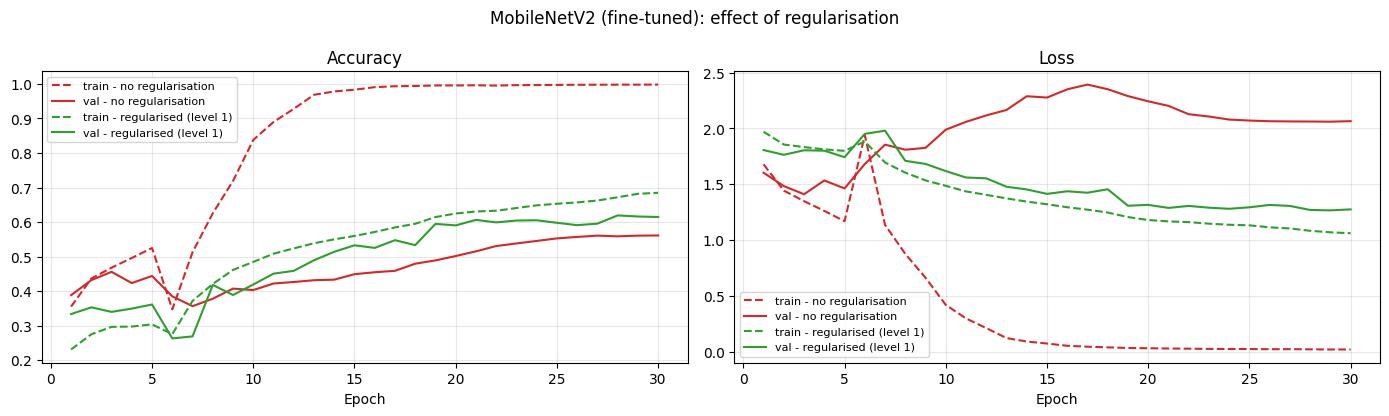

,Version,Train acc,Val acc,Gap,Test acc,Diagnosis
0,No regularisation (level 0),1.000,0.561,0.438,0.576,overfitting
1,Regularised (level 1),0.674,0.620,0.054,0.608,good fit


In [14]:
if RUN_BEFORE_AFTER:
    r0 = run_experiment("MobileNetV2", "finetune", level=0)
    r1 = RESULTS["MobileNetV2|finetune|L1"]

    fig, ax = plt.subplots(1, 2, figsize=(14, 4.2))
    for r, lab, col in [(r0, "no regularisation", "tab:red"), (r1, "regularised (level 1)", "tab:green")]:
        ep = np.arange(1, len(r["history"]["accuracy"]) + 1)
        ax[0].plot(ep, r["history"]["accuracy"], color=col, ls="--", label=f"train - {lab}")
        ax[0].plot(ep, r["history"]["val_accuracy"], color=col, label=f"val - {lab}")
        ax[1].plot(ep, r["history"]["loss"], color=col, ls="--", label=f"train - {lab}")
        ax[1].plot(ep, r["history"]["val_loss"], color=col, label=f"val - {lab}")
    ax[0].set_title("Accuracy")
    ax[1].set_title("Loss")
    for a in ax:
        a.set_xlabel("Epoch")
        a.grid(alpha=0.3)
        a.legend(fontsize=8)
    plt.suptitle("MobileNetV2 (fine-tuned): effect of regularisation")
    plt.tight_layout()
    plt.show()

    display(pd.DataFrame([
        {"Version": "No regularisation (level 0)", "Train acc": r0["train_acc"], "Val acc": r0["val_acc"],
         "Gap": r0["gap"], "Test acc": r0["test_acc"], "Diagnosis": r0["diagnosis"]},
        {"Version": "Regularised (level 1)", "Train acc": r1["train_acc"], "Val acc": r1["val_acc"],
         "Gap": r1["gap"], "Test acc": r1["test_acc"], "Diagnosis": r1["diagnosis"]},
    ]).round(3))

## G. Comparison of all models and modes
All numbers below use the **final** version of each run (level 1, or level 2 if the overfitting fix was better on validation).

,Model,Mode,Reg. level,Trainable params (M),Best epoch,Train acc,Val acc,Gap,Test acc,Test acc (leak-free),Macro-F1,Weighted-F1,Diagnosis,Time (min)
0,VGG16,frozen,1,0.13,14,0.418,0.410,0.008,0.405,0.402,0.339,0.382,underfitting,11.598
1,VGG16,fine-tuned,1,14.85,28,0.649,0.625,0.024,0.617,0.606,0.598,0.615,good fit,30.421
2,ResNet50,frozen,1,0.53,27,0.468,0.447,0.021,0.462,0.449,0.405,0.453,underfitting,12.749
3,ResNet50,fine-tuned,1,24.06,30,0.784,0.640,0.145,0.646,0.630,0.638,0.648,good fit,43.428
4,MobileNetV2,frozen,1,0.33,20,0.393,0.391,0.002,0.395,0.389,0.338,0.377,underfitting,5.504
5,MobileNetV2,fine-tuned,1,2.55,28,0.674,0.620,0.054,0.608,0.595,0.578,0.609,good fit,21.991


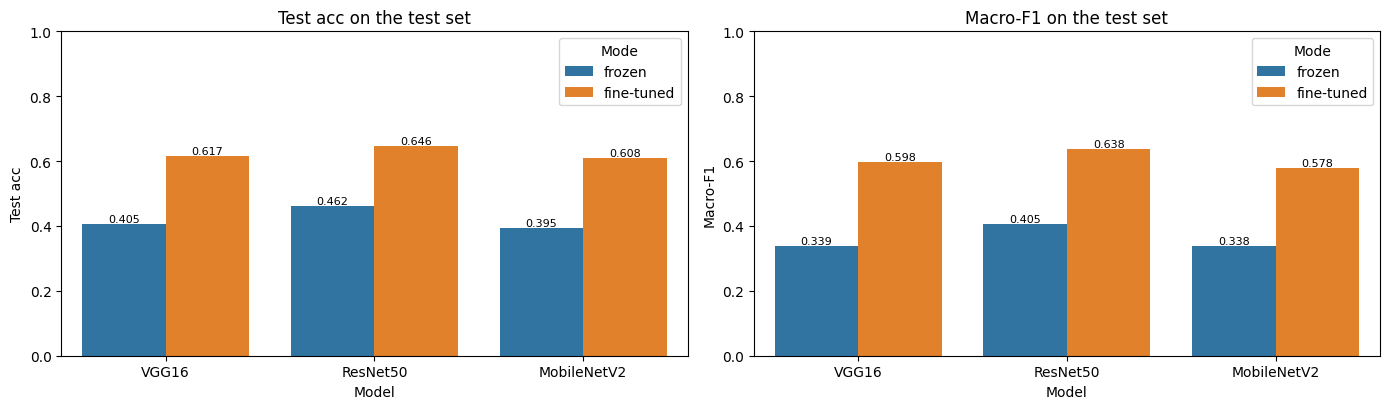

In [15]:
rows = []
for name in MODEL_ZOO:
    for mode in MODES:
        r = get_final(name, mode)
        rows.append({
            "Model": name, "Mode": "fine-tuned" if mode == "finetune" else "frozen",
            "Reg. level": r["level"], "Trainable params (M)": round(r["trainable_params"] / 1e6, 2),
            "Best epoch": r["best_epoch"], "Train acc": r["train_acc"], "Val acc": r["val_acc"],
            "Gap": r["gap"], "Test acc": r["test_acc"], "Test acc (leak-free)": r["clean_test_acc"],
            "Macro-F1": r["macro_f1"], "Weighted-F1": r["weighted_f1"],
            "Diagnosis": r["diagnosis"], "Time (min)": r["minutes"],
        })
summary = pd.DataFrame(rows)
display(summary.round(3))
summary.round(4).to_csv(os.path.join(OUT_DIR, "submission2_summary.csv"), index=False)

fig, ax = plt.subplots(1, 2, figsize=(14, 4.2))
for a, col in zip(ax, ["Test acc", "Macro-F1"]):
    sns.barplot(data=summary, x="Model", y=col, hue="Mode", ax=a)
    a.set_ylim(0, 1)
    a.set_title(f"{col} on the test set")
    for c in a.containers:
        a.bar_label(c, fmt="%.3f", fontsize=8)
plt.tight_layout()
plt.show()

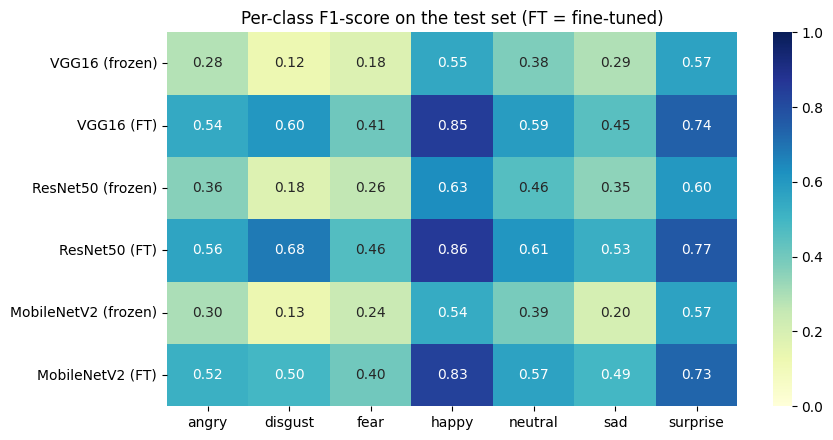

In [16]:
# Per-class F1 of every final run (shows which emotions are easy / hard)
f1_rows, labels_ = [], []
for name in MODEL_ZOO:
    for mode in MODES:
        r = get_final(name, mode)
        f1_rows.append(f1_score(y_test, r["test_probs"].argmax(1), average=None, labels=range(NUM_CLASSES)))
        labels_.append(f"{name} ({'FT' if mode == 'finetune' else 'frozen'})")
plt.figure(figsize=(9, 4.5))
sns.heatmap(pd.DataFrame(f1_rows, index=labels_, columns=classes), annot=True, fmt=".2f", cmap="YlGnBu", vmin=0, vmax=1)
plt.title("Per-class F1-score on the test set (FT = fine-tuned)")
plt.tight_layout()
plt.show()

### G.1 Findings generated from our own results

In [17]:
best_row = summary.sort_values("Macro-F1", ascending=False).iloc[0]
print(f"1. Best test result: {best_row['Model']} ({best_row['Mode']}) with accuracy {best_row['Test acc']:.3f} and macro-F1 {best_row['Macro-F1']:.3f}.\n")

print("2. Effect of fine-tuning (test accuracy, frozen -> fine-tuned):")
for name in MODEL_ZOO:
    a, b = get_final(name, "frozen")["test_acc"], get_final(name, "finetune")["test_acc"]
    print(f"   {name:12s} {a:.3f} -> {b:.3f}   ({(b - a) * 100:+.1f} percentage points)")

print("\n3. Hardest and easiest emotion for the best model (F1 on the test set):")
best_res = get_final(best_row["Model"], "finetune" if best_row["Mode"] == "fine-tuned" else "frozen")
f1c = f1_score(y_test, best_res["test_probs"].argmax(1), average=None, labels=range(NUM_CLASSES))
print(f"   easiest: {classes[int(np.argmax(f1c))]} (F1 {f1c.max():.2f}) | hardest: {classes[int(np.argmin(f1c))]} (F1 {f1c.min():.2f})")

cm = confusion_matrix(y_test, best_res["test_probs"].argmax(1), labels=range(NUM_CLASSES)).astype(float)
cm = cm / cm.sum(axis=1, keepdims=True)
np.fill_diagonal(cm, 0)
pairs = sorted(((cm[i, j], classes[i], classes[j]) for i in range(NUM_CLASSES) for j in range(NUM_CLASSES) if i != j), reverse=True)[:3]
print("\n4. Most confused pairs (share of the true class predicted as the other class):")
for v, t, p in pairs:
    print(f"   {t} -> {p}: {v * 100:.1f}%")

print(f"\n5. Data leakage effect: official test acc {best_row['Test acc']:.3f} vs leak-free test acc {best_row['Test acc (leak-free)']:.3f}. "
      "A higher official number means some of the score comes from images the model has already seen in training.")

1. Best test result: ResNet50 (fine-tuned) with accuracy 0.646 and macro-F1 0.638.

2. Effect of fine-tuning (test accuracy, frozen -> fine-tuned):
   VGG16        0.405 -> 0.617   (+21.3 percentage points)
   ResNet50     0.462 -> 0.646   (+18.4 percentage points)
   MobileNetV2  0.395 -> 0.608   (+21.4 percentage points)

3. Hardest and easiest emotion for the best model (F1 on the test set):
   easiest: happy (F1 0.86) | hardest: fear (F1 0.46)

4. Most confused pairs (share of the true class predicted as the other class):
   fear -> sad: 20.8%
   sad -> neutral: 17.7%
   neutral -> sad: 16.8%

5. Data leakage effect: official test acc 0.646 vs leak-free test acc 0.630. A higher official number means some of the score comes from images the model has already seen in training.


## Ensemble of the three fine-tuned models

Ensemble test accuracy: 0.6590 | leak-free: 0.6448 | macro-F1: 0.6445

Ensemble of VGG16 + ResNet50 + MobileNetV2 (all fine-tuned)
Test accuracy: 0.6590
              precision    recall  f1-score   support

       angry      0.571     0.599     0.585       958
     disgust      0.696     0.640     0.667       111
        fear      0.508     0.415     0.457      1024
       happy      0.888     0.856     0.872      1774
     neutral      0.587     0.664     0.623      1233
         sad      0.522     0.538     0.530      1247
    surprise      0.773     0.783     0.778       831

    accuracy                          0.659      7178
   macro avg      0.649     0.642     0.644      7178
weighted avg      0.660     0.659     0.658      7178



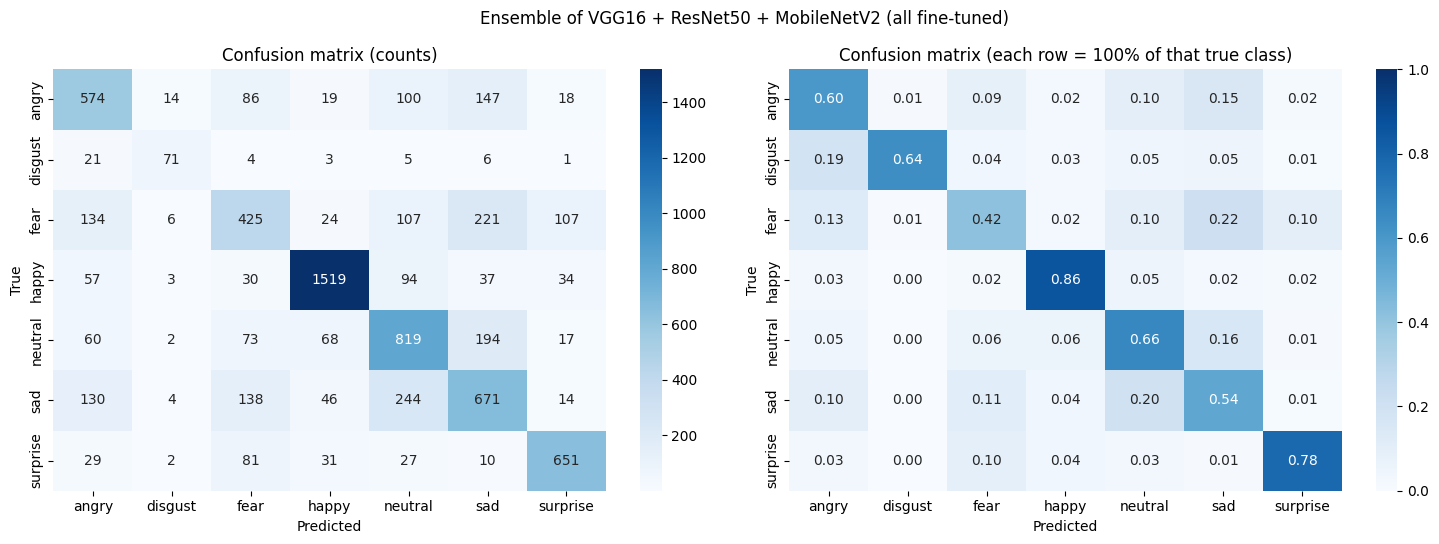

In [18]:
ens_probs = np.mean([get_final(n, "finetune")["test_probs"] for n in MODEL_ZOO], axis=0)
ens_pred = ens_probs.argmax(1)
print(f"Ensemble test accuracy: {accuracy_score(y_test, ens_pred):.4f} | "
      f"leak-free: {accuracy_score(y_test[~leak_mask], ens_pred[~leak_mask]):.4f} | "
      f"macro-F1: {f1_score(y_test, ens_pred, average='macro'):.4f}")
show_report(ens_probs, "Ensemble of VGG16 + ResNet50 + MobileNetV2 (all fine-tuned)")

## H. Choosen architecture for this project
We choose the architecture using **validation** results (not the test set, so the test set stays an honest final check), and then look at test performance, overfitting gap, minority-class (disgust) recall and model size.

In [19]:
cand = summary.copy()
for i, row in cand.iterrows():
    r = get_final(row["Model"], "finetune" if row["Mode"] == "fine-tuned" else "frozen")
    cand.loc[i, "Val macro-F1"] = r["val_macro_f1"]
    cand.loc[i, "Disgust recall"] = (r["test_probs"].argmax(1)[y_test == 1] == 1).mean()
    cand.loc[i, "Total params (M)"] = MODEL_ZOO[row["Model"]]["builder"](
        include_top=False, weights=None, input_shape=(IMG_SIZE, IMG_SIZE, 3)).count_params() / 1e6

show = cand[["Model", "Mode", "Val acc", "Val macro-F1", "Test acc", "Macro-F1", "Disgust recall", "Gap", "Total params (M)", "Time (min)"]]
display(show.sort_values("Val macro-F1", ascending=False).round(3))

top = cand.sort_values("Val macro-F1", ascending=False).iloc[0]
small = cand[cand["Model"] == "MobileNetV2"].sort_values("Val macro-F1", ascending=False).iloc[0]
print(f"\nRECOMMENDED (best validation macro-F1): {top['Model']} - {top['Mode']}  "
      f"(test acc {top['Test acc']:.3f}, macro-F1 {top['Macro-F1']:.3f})")
print(f"Best lightweight option for the real-time demo: MobileNetV2 - {small['Mode']}  "
      f"(test acc {small['Test acc']:.3f}, macro-F1 {small['Macro-F1']:.3f}, {small['Total params (M)']:.1f} M parameters)")

,Model,Mode,Val acc,Val macro-F1,Test acc,Macro-F1,Disgust recall,Gap,Total params (M),Time (min)
3,ResNet50,fine-tuned,0.640,0.599,0.646,0.638,0.739,0.145,23.588,43.428
1,VGG16,fine-tuned,0.625,0.586,0.617,0.598,0.568,0.024,14.715,30.421
5,MobileNetV2,fine-tuned,0.620,0.576,0.608,0.578,0.459,0.054,2.258,21.991
2,ResNet50,frozen,0.447,0.391,0.462,0.405,0.333,0.021,23.588,12.749
0,VGG16,frozen,0.410,0.340,0.405,0.339,0.126,0.008,14.715,11.598
4,MobileNetV2,frozen,0.391,0.331,0.395,0.338,0.153,0.002,2.258,5.504



RECOMMENDED (best validation macro-F1): ResNet50 - fine-tuned  (test acc 0.646, macro-F1 0.638)
Best lightweight option for the real-time demo: MobileNetV2 - fine-tuned  (test acc 0.608, macro-F1 0.578, 2.3 M parameters)



## J. Conclusion
1. We fine-tuned three pretrained CNNs (VGG16, ResNet50, MobileNetV2) with and without fine-tuning for 30 epochs each and evaluated them with curves, classification reports and confusion matrices.
2. We diagnosed overfitting and underfitting automatically and fixed them with stronger regularisation (augmentation, dropout, L2, label smoothing) and by fine-tuning.
3. We found and handled data issues from Submission 1 (duplicates, conflicting labels, test-train leakage) and reported leak-free test accuracy.
4. Next steps: tune the best model (learning rate, unfreezing depth, input size), add Grad-CAM to show where the model looks, and build the live webcam demo with the recommended architecture.

## References
1. K. Simonyan and A. Zisserman, "Very Deep Convolutional Networks for Large-Scale Image Recognition" (VGG), 2014. https://arxiv.org/abs/1409.1556
2. K. He, X. Zhang, S. Ren and J. Sun, "Deep Residual Learning for Image Recognition" (ResNet), 2015. https://arxiv.org/abs/1512.03385
3. M. Sandler et al., "MobileNetV2: Inverted Residuals and Linear Bottlenecks," 2018. https://arxiv.org/abs/1801.04381
4. J. Yosinski, J. Clune, Y. Bengio and H. Lipson, "How transferable are features in deep neural networks?," 2014. https://arxiv.org/abs/1411.1792
5. Y. Khaireddin and Z. Chen, "Facial Emotion Recognition: State of the Art Performance on FER2013," 2021. https://arxiv.org/abs/2105.03588
6. C. Pramerdorfer and M. Kampel, "Facial Expression Recognition using Convolutional Neural Networks: State of the Art," 2016. https://arxiv.org/abs/1612.02903
7. I. J. Goodfellow et al., "Challenges in Representation Learning: A report on three machine learning contests," 2013. https://arxiv.org/abs/1307.0414
8. FER-2013 image-folder version on Kaggle. https://www.kaggle.com/datasets/msambare/fer2013